# Phase 10 — External validity: does a 2011-12 result survive?

[`walkthrough/phase10.md`](../walkthrough/phase10.md). No public survey records both income and consumption for the same
households after 2011-12, so an out-of-time test of the *classifier* is not possible. Three things are testable instead:

1. **The leakage mechanism on a newer survey.** HCES 2022-23 has consumption but no income. It can still say whether food
   spend is as tightly tied to household size as in IHDS-II, which is the ingredient of the composition leak.
   (Needs `dataset/hces/level_{01,03,14}.parquet`; see `dataset/README.md`. The cell is skipped if they are absent.)
2. **A simulation** of the oracle's ROC-AUC against that ingredient, so any survey can be placed on one curve.
3. **Transport inside IHDS-II**: whole states held out, and rural-to-urban and urban-to-rural, as stand-ins for
   "the population changes under the model".

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from savings_goal import config as C
from savings_goal import viz
from savings_goal.data import hces
from savings_goal.evaluation import leakage_sim as LS
from savings_goal.evaluation import transport
from savings_goal.evaluation.leakage import size_share_oracle
from savings_goal.evaluation.metrics import weighted_mean
from savings_goal.features.engineer import spec_from_frame
from savings_goal.io import load_features, load_households, write_result
from savings_goal.models.pipeline import load_model_final, xgb_pipeline

viz.use()
hh = load_households()
hh["sector"] = np.where(hh["Area_Type"].isin(["Metro_Urban", "Other_Urban"]), "urban", "rural")
oracle = size_share_oracle(hh)
print(f"IHDS-II oracle (empirical, income available): ROC-AUC {oracle.auc:.3f}")

IHDS-II oracle (empirical, income available): ROC-AUC 0.895


## 1. The mechanism in IHDS-II (2011-12) and HCES (2022-23)

In [2]:
def mech(food, size, total, w, label):
    fit = LS.residual_sd(food, size)
    rec = hces.oracle_reconstruction(food, total, size)
    share = weighted_mean((food / total).to_numpy(), w.to_numpy())
    implied = LS.oracle_auc(fit["sigma"], fit["elasticity"])
    return {"survey": label, "n": len(food), **fit, **rec, "food_share_weighted": share,
            "implied_oracle_auc": implied}


rows = [mech(g["Groceries"], g["Household_Size"], g["Category_Total"], g["WT"], f"IHDS-II 2011-12 {s}")
        for s, g in hh.groupby("sector")]
rows.insert(0, mech(hh["Groceries"], hh["Household_Size"], hh["Category_Total"], hh["WT"], "IHDS-II 2011-12 all"))
try:
    hc = hces.household_table(C.DATASET / "hces")
    rows += [mech(g["food"], g["hh_size"], g["total"], g["weight"], f"HCES 2022-23 {s}") for s, g in hc.groupby("sector")]
    rows.insert(len(rows) - 2, mech(hc["food"], hc["hh_size"], hc["total"], hc["weight"], "HCES 2022-23 all"))
    mpce = hces.weighted_mpce(hc)
    print("HCES 2022-23 MPCE (Rs/month, replicates the NSO factsheet):", {k: round(v) for k, v in mpce.items()})
except FileNotFoundError:
    print("HCES files not found: mechanism comparison skipped (see dataset/README.md).")
    mpce = None
mech_tbl = pd.DataFrame(rows).set_index("survey")
print(mech_tbl.round(3).to_string())

# Nominal monthly per-capita expenditure, 2011-12 vs 2022-23 (not deflated: CPI is not in either file).
ihds_mpce = {s: float((g["WT"] * g["COTOTAL"] / 12).sum() / (g["WT"] * g["Household_Size"]).sum())
             for s, g in hh.groupby("sector")}
print("\nIHDS-II 2011-12 MPCE (Rs/month, nominal):", {k: round(v) for k, v in ihds_mpce.items()})
if mpce:
    print("nominal growth to 2022-23:", {k: round(mpce[k] / ihds_mpce[k], 2) for k in ihds_mpce})

HCES 2022-23 MPCE (Rs/month, replicates the NSO factsheet): {'rural': 3773, 'urban': 6459}
                            n  elasticity  sigma     r2  spearman  median_abs_log_error  food_share_weighted  implied_oracle_auc
survey                                                                                                                          
IHDS-II 2011-12 all     41518       0.630  0.485  0.292     0.670                 0.341                0.466               0.868
IHDS-II 2011-12 rural   27045       0.653  0.483  0.321     0.661                 0.334                0.491               0.869
IHDS-II 2011-12 urban   14473       0.587  0.440  0.280     0.681                 0.314                0.416               0.879
HCES 2022-23 all       261746       0.565  0.472  0.295     0.556                 0.331                0.465               0.868
HCES 2022-23 rural     155014       0.663  0.439  0.375     0.589                 0.298                0.485               0.884
HCES 2

`implied_oracle_auc` is the simulated oracle ROC-AUC at each survey's measured elasticity and residual sd, holding the income-to-consumption dispersion at the IHDS-II value. It is a prediction about the leak under that assumption, not a measured AUC: HCES has no income, so the label cannot be built.

## 2. The leakage curve

elasticity   0.63   1.00
sigma                   
0.0         0.976  1.000
0.1         0.970  0.992
0.2         0.951  0.971
0.3         0.925  0.941
0.4         0.894  0.907
0.5         0.863  0.873
0.6         0.833  0.841
0.8         0.782  0.787
1.0         0.742  0.745
1.5         0.675  0.676


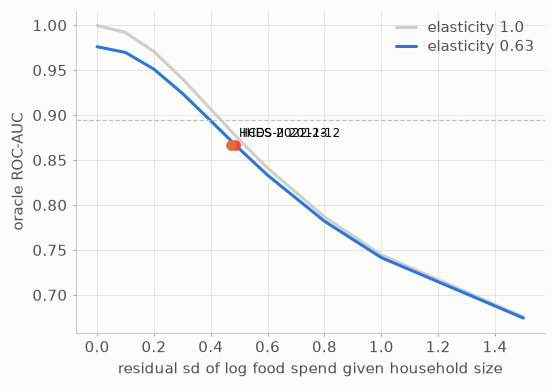

In [3]:
grid = LS.auc_grid()
print(grid.pivot(index="sigma", columns="elasticity", values="oracle_auc").round(3).to_string())

fig, ax = plt.subplots(figsize=(5.5, 3.8))
for e, colr in ((1.0, viz.CONTEXT), (0.63, viz.BLUE)):
    g = grid[grid["elasticity"] == e]
    ax.plot(g["sigma"], g["oracle_auc"], color=colr, lw=2, label=f"elasticity {e}")
for name, r in mech_tbl.iterrows():
    if name.endswith("all"):
        ax.scatter(r["sigma"], r["implied_oracle_auc"], zorder=5, s=36, color=viz.ORANGE if "HCES" in name else viz.RED)
        ax.annotate(name.replace(" all", ""), (r["sigma"], r["implied_oracle_auc"]), xytext=(5, 5),
                    textcoords="offset points", fontsize=8)
ax.axhline(oracle.auc, color=viz.AXIS, lw=0.8, ls="--")
ax.set_xlabel("residual sd of log food spend given household size")
ax.set_ylabel("oracle ROC-AUC")
viz.strip(ax, "both")
viz.legend(ax, loc="upper right")
plt.savefig(C.RESULTS / "leakage_curve.png")
plt.show()

## 3. Transport inside IHDS-II

In [4]:
feats = load_features()
spec = spec_from_frame(feats)
final = load_model_final()
df = feats.assign(sector=np.where(feats["Area_Type"].isin(["Metro_Urban", "Other_Urban"]), "urban", "rural"))
cols = spec.deployable_numeric + C.CATEGORICALS
model = xgb_pipeline(spec.deployable_numeric, params=final["deployable"]["best_params"])

by_state = transport.leave_group_out(df, "STATEID", model, cols, n_splits=5)
print("Leave-states-out (5 folds of whole states):")
print(by_state.round(3).to_string(index=False))

rural, urban = (df["sector"] == "rural").to_numpy(), (df["sector"] == "urban").to_numpy()
shifts = pd.DataFrame([
    {"shift": "train rural -> test urban", **transport.shift_test(df, rural, urban, model, cols)},
    {"shift": "train urban -> test rural", **transport.shift_test(df, urban, rural, model, cols)},
])
print("\nSector shift:")
print(shifts.round(3).to_string(index=False))

Leave-states-out (5 folds of whole states):
 fold  groups_held_out  n_train  n_test  at_risk_rate  ROC-AUC   ECE  calibration_in_the_large  recall@25% model  precision@25% model  recall@25% income rule
    0                7  33207.0  8311.0         0.723    0.890 0.025                     0.024             0.342                0.988                   0.335
    1                8  33185.0  8333.0         0.662    0.871 0.023                    -0.001             0.372                0.985                   0.361
    2                5  33242.0  8276.0         0.627    0.877 0.071                    -0.071             0.389                0.976                   0.373
    3                7  33238.0  8280.0         0.736    0.888 0.039                     0.039             0.337                0.992                   0.330
    4                6  33200.0  8318.0         0.656    0.871 0.018                     0.007             0.374                0.980                   0.359



Sector shift:
                    shift  n_train  n_test  at_risk_rate  ROC-AUC   ECE  calibration_in_the_large  recall@25% model  precision@25% model  recall@25% income rule
train rural -> test urban  27045.0 14473.0         0.619    0.866 0.091                     0.091             0.391                0.968                   0.375
train urban -> test rural  14473.0 27045.0         0.714    0.882 0.048                    -0.048             0.346                0.988                   0.337


In [5]:
write_result("external_validity", {
    "mechanism": mech_tbl.reset_index(),
    "hces_mpce_rs_per_month": mpce,
    "ihds_mpce_rs_per_month": ihds_mpce,
    "oracle_ihds": {"auc": oracle.auc, "k": oracle.k},
    "leakage_curve": grid,
    "leave_states_out": by_state,
    "sector_shift": shifts,
    "note": "HCES 2022-23 has no income: the mechanism is compared, the label is not rebuilt.",
})

WindowsPath('C:/Users/arish/Documents/Github/savings-goal-classifier/.claude/worktrees/savings-classifier-feedback-25aed3/results/external_validity.json')